در حال بارگذاری داده‌ها...


C:\Users\FarzanMD\AppData\Local\Temp\ipykernel_26276\1430260141.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='hour', palette='Blues')  # 'Blues' یا حذف palette


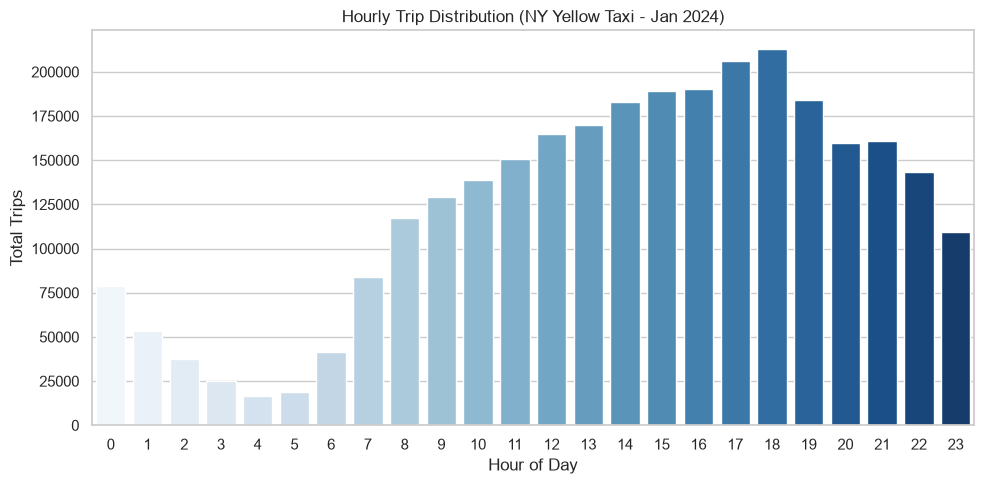

C:\Users\FarzanMD\AppData\Local\Temp\ipykernel_26276\1430260141.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dayofweek', order=days_order, palette='viridis')  # ویرایش به حروف کوچک


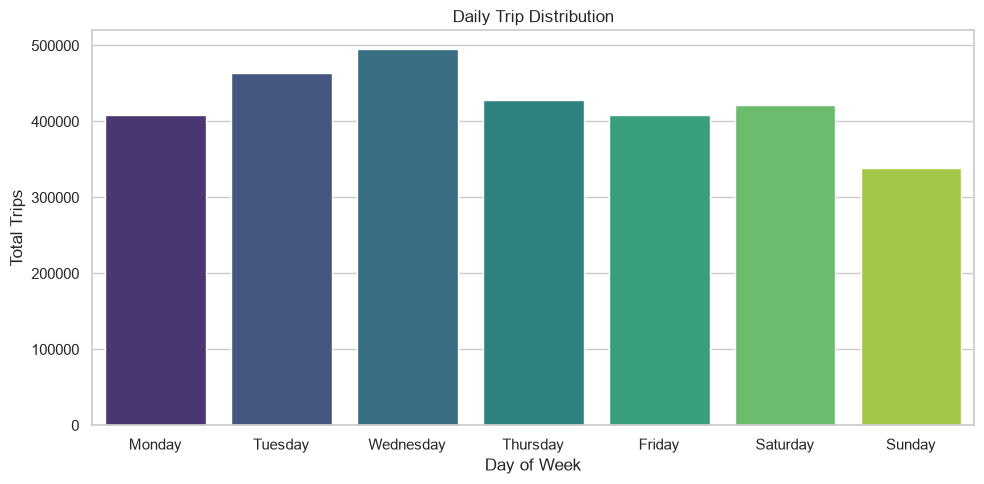

C:\Users\FarzanMD\AppData\Local\Temp\ipykernel_26276\1430260141.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.index, y=top_locations.values, order=top_locations.index, palette='magma')  # ویرایش به حروف کوچک


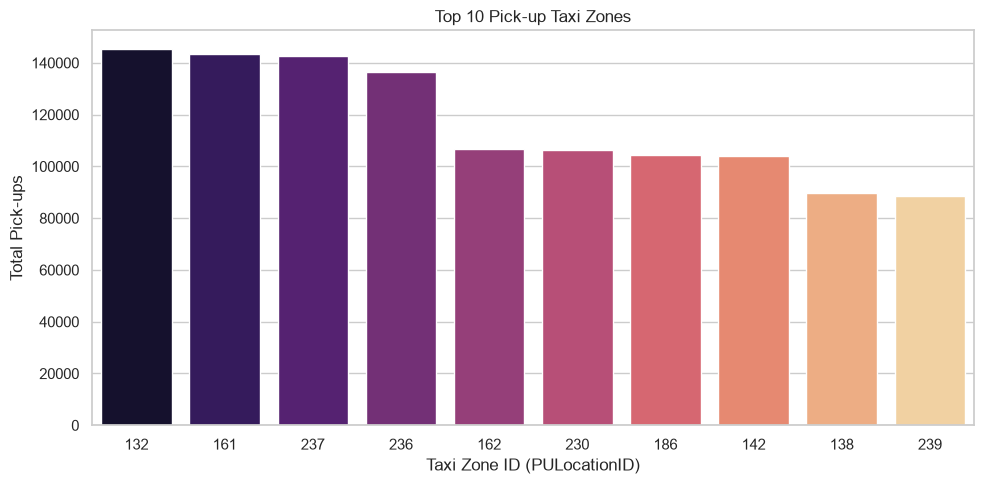

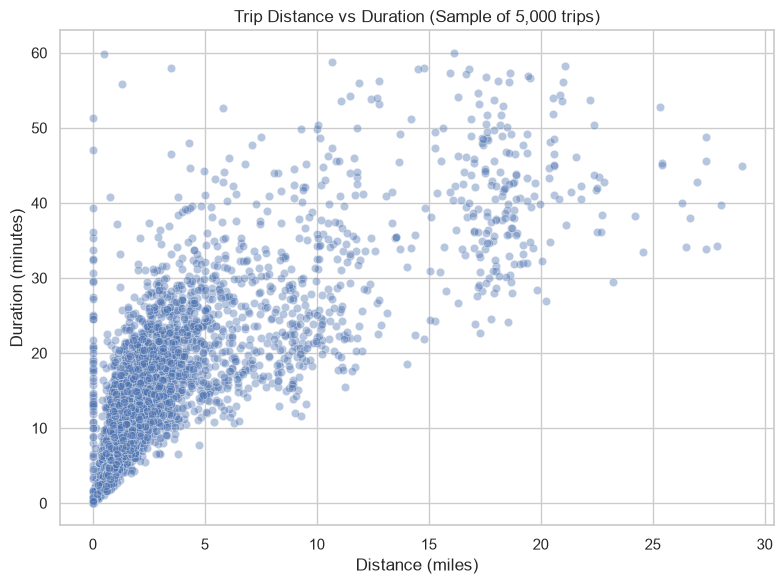

تحلیل و ذخیره نمودارها با موفقیت انجام شد!


In [4]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیمات نمایش و انکودینگ
#sys.stdout.reconfigure(encoding='utf-8')
sns.set_theme(style="whitegrid")

# ایجاد پوشه figures در صورت عدم وجود
os.makedirs("../figures", exist_ok=True)

# بارگذاری داده نمونه
sample_url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
print("در حال بارگذاری داده‌ها...")
df = pd.read_parquet(sample_url)

# ۱. استخراج ویژگی‌های زمانی اولیه
df['pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['dayofweek'] = df['pickup_datetime'].dt.day_name()
df['trip_duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0
# ۲. نمودار توزیع ساعتی سفرها (ممیزی زمان)
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='hour', palette='Blues')  # 'Blues' یا حذف palette
plt.title('Hourly Trip Distribution (NY Yellow Taxi - Jan 2024)')
plt.xlabel('Hour of Day')
plt.ylabel('Total Trips')
plt.tight_layout()
plt.savefig('../figures/hourly_trip_distribution.png', dpi=300)
plt.show()

# ۳. نمودار توزیع سفرها در روزهای هفته
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='dayofweek', order=days_order, palette='viridis')  # ویرایش به حروف کوچک
plt.title('Daily Trip Distribution')
plt.xlabel('Day of Week')
plt.ylabel('Total Trips')
plt.tight_layout()
plt.savefig('../figures/daily_trip_distribution.png', dpi=300)
plt.show()

# ۴. ممیزی مکانی: ۱۰ منطقه پرتقاضای مبدأ (PULocationID)
plt.figure(figsize=(10, 5))
top_locations = df['PULocationID'].value_counts().head(10)
sns.barplot(x=top_locations.index, y=top_locations.values, order=top_locations.index, palette='magma')  # ویرایش به حروف کوچک
plt.title('Top 10 Pick-up Taxi Zones')
plt.xlabel('Taxi Zone ID (PULocationID)')
plt.ylabel('Total Pick-ups')
plt.tight_layout()
plt.savefig('../figures/top_pickup_zones.png', dpi=300)
plt.show()
# ۵. بررسی سازگاری متغیرها: مسافت در برابر مدت زمان سفر (محدود شده به سفرهای زیر ۶۰ دقیقه)
clean_subset = df[(df['trip_duration_min'] > 0) & (df['trip_duration_min'] <= 60) & (df['trip_distance'] <= 30)]
plt.figure(figsize=(8, 6))
sns.scatterplot(data=clean_subset.sample(5000, random_state=42), x='trip_distance', y='trip_duration_min', alpha=0.4)
plt.title('Trip Distance vs Duration (Sample of 5,000 trips)')
plt.xlabel('Distance (miles)')
plt.ylabel('Duration (minutes)')
plt.tight_layout()
plt.savefig('../figures/distance_vs_duration.png', dpi=300)
plt.show()

print("تحلیل و ذخیره نمودارها با موفقیت انجام شد!")